In [5]:
%pip install fastf1 pandas matplotlib numpy

Note: you may need to restart the kernel to use updated packages.


In [6]:
import fastf1
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
import fastf1
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("FastF1 version:", fastf1.__version__)
print("All libraries are ready!")

FastF1 version: 3.8.3
All libraries are ready!


In [8]:
from pathlib import Path

project_dir = Path.cwd()

(project_dir / "data").mkdir(exist_ok=True)
(project_dir / "figures").mkdir(exist_ok=True)

print("Project folder:", project_dir)
print("Data and figures folders created!")

Project folder: C:\Users\yazda
Data and figures folders created!


In [9]:
import fastf1
from pathlib import Path

# Enable caching so downloaded data can be reused
fastf1.Cache.enable_cache(str(Path("data") / "cache"))

# Load the 2024 British Grand Prix qualifying session
session = fastf1.get_session(2024, "British Grand Prix", "Q")
session.load()

print("Session loaded successfully!")
print("Event:", session.event["EventName"])
print("Available drivers:", sorted(session.laps["Driver"].dropna().unique()))

NotADirectoryError: Cache directory does not exist! Please check for typos or create it first.

In [10]:
from pathlib import Path

Path("data/cache").mkdir(parents=True, exist_ok=True)

print("Cache folder created successfully!")

Cache folder created successfully!


In [11]:
import fastf1
from pathlib import Path

fastf1.Cache.enable_cache(str(Path("data/cache")))

session = fastf1.get_session(
    2024,
    "British Grand Prix",
    "Q"
)

session.load()

print("Session loaded successfully!")
print("Event:", session.event["EventName"])
print(
    "Available drivers:",
    sorted(session.laps["Driver"].dropna().unique())
)

core           INFO 	Loading data for British Grand Prix - Qualifying [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
logger      WARNING 	Failed to load session status data!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
logger      WARNING 	Failed to load track status data!
req            INFO 	No cached data found for _extended_timing_data. Loading data...
_api           INFO 	Fetching timing data...
logger      WARNING 	Failed to load timing d

Session loaded successfully!
Event: British Grand Prix


DataNotLoadedError: The data you are trying to access has not been loaded yet. See `Session.load`

In [12]:
import fastf1
from pathlib import Path

fastf1.Cache.enable_cache(str(Path("data/cache")))

session = fastf1.get_session(
    2024, "British Grand Prix", "Q"
)

session.load(
    laps=True,
    telemetry=False,
    weather=False,
    messages=False
)

print("Loaded laps:", len(session.laps))
print(session.laps[["Driver", "LapNumber", "LapTime"]].head(10))

core           INFO 	Loading data for British Grand Prix - Qualifying [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
logger      WARNING 	Failed to load session status data!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
logger      WARNING 	Failed to load track status data!
req            INFO 	No cached data found for _extended_timing_data. Loading data...
_api           INFO 	Fetching timing data...
logger      WARNING 	Failed to load timing d

DataNotLoadedError: The data you are trying to access has not been loaded yet. See `Session.load`

In [13]:
import requests

url = "https://api.github.com"

try:
    response = requests.get(url, timeout=15)
    print("Internet test status:", response.status_code)
except Exception as e:
    print("Connection problem:", repr(e))

Internet test status: 200


In [14]:
import fastf1
import logging

fastf1.set_log_level("DEBUG")

session = fastf1.get_session(
    2024, "British Grand Prix", "Q"
)

try:
    session.load(
        laps=True,
        telemetry=False,
        weather=False,
        messages=False
    )
    print("Lap data loaded:", len(session.laps))
except Exception as e:
    print("ERROR TYPE:", type(e).__name__)
    print("ERROR DETAILS:", str(e))

core           INFO 	Loading data for British Grand Prix - Qualifying [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
_api          DEBUG 	Falling back to livetiming mirror (https://livetiming-mirror.fastf1.dev)
logger      WARNING 	Failed to load session info data!
logger        DEBUG 	Traceback for failure in session info data
Traceback (most recent call last):
  File "C:\Users\yazda\AppData\Local\Programs\Python\Python314\Lib\site-packages\fastf1\logger.py", line 112, in __wrapped
    return func(*args, **kwargs)
  File "C:\Users\yazda\AppData\Local\Programs\Python\Python314\Lib\site-packages\fastf1\core.py", line 1452, in _load_session_info
    self._session_info = api.session_info(self.api_path,
                         ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
                                          livedata=livedata)
                                          ^^^^^^^^^^^^^^^^^^
  File "C:\Users\yazda\

ERROR TYPE: DataNotLoadedError
ERROR DETAILS: The data you are trying to access has not been loaded yet. See `Session.load`


In [15]:
import requests

base = (
    "https://livetiming.formula1.com/"
    "static/2024/2024-07-07_British_Grand_Prix/"
    "2024-07-06_Qualifying/"
)

for filename in [
    "SessionInfo.jsonStream",
    "TimingData.jsonStream"
]:
    try:
        response = requests.get(
            base + filename,
            headers={"User-Agent": "Mozilla/5.0"},
            timeout=15
        )
        print(filename, response.status_code)
    except Exception as e:
        print(filename, type(e).__name__, str(e))

SessionInfo.jsonStream 401
TimingData.jsonStream 401


In [16]:
import fastf1

fastf1.set_log_level("INFO")

session = fastf1.get_session(2024, "Belgian Grand Prix", "R")
session.load(laps=True, telemetry=False, weather=False, messages=False)

print("Loaded laps:", len(session.laps))
print(session.laps[["Driver", "LapNumber", "LapTime"]].head())


core           INFO 	Loading data for Belgian Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
logger      WARNING 	Failed to load session status data!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
logger      WARNING 	Failed to load total lap count!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
logger      WARNING 	Failed to load track status data!
req   

DataNotLoadedError: The data you are trying to access has not been loaded yet. See `Session.load`

In [17]:
import requests

url = (
    "https://livetiming.formula1.com/static/"
    "2024/2024-07-07_British_Grand_Prix/"
    "2024-07-06_Qualifying/SessionInfo.jsonStream"
)

for agent in ["BestHTTP", "Mozilla/5.0"]:
    try:
        r = requests.get(
            url,
            headers={"User-Agent": agent},
            timeout=15
        )
        print(agent, "->", r.status_code)
    except Exception as e:
        print(type(e).__name__, str(e))

BestHTTP -> 401
Mozilla/5.0 -> 401


In [18]:
%pip install tif1

  Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl.metadata (19 kB)
   ---------------------------------------- 0.0/4.9 MB ? eta -:--:--
   -------- ------------------------------- 1.0/4.9 MB 12.2 MB/s eta 0:00:01
   -------- ------------------------------- 1.0/4.9 MB 12.2 MB/s eta 0:00:01
   -------- ------------------------------- 1.0/4.9 MB 12.2 MB/s eta 0:00:01
   ------------ --------------------------- 1.6/4.9 MB 1.6 MB/s eta 0:00:03
   ----------------- ---------------------- 2.1/4.9 MB 2.2 MB/s eta 0:00:02
   ----------------- ---------------------- 2.1/4.9 MB 2.2 MB/s eta 0:00:02
   ------------------- -------------------- 2.4/4.9 MB 1.5 MB/s eta 0:00:02
   ------------------------- -------------- 3.1/4.9 MB 1.9 MB/s eta 0:00:01
   ---------------------------------- ----- 4.2/4.9 MB 2.2 MB/s eta 0:00:01
   ---------------------------------- ----- 4.2/4.9 MB 2.2 MB/s eta 0:00:01
   ---------------------------------- ----- 4.2/4.9 MB 2.2 MB/s eta 0:00:01
   ------------------

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
fastf1 3.8.3 requires pandas<3.0.0,>=2.1.1, but you have pandas 3.0.6 which is incompatible.


In [19]:
import tif1

print("TIF1 imported successfully")
print(dir(tif1))

TIF1 imported successfully
['Any', 'CacheError', 'CircuitBreakerOpenError', 'DataNotFoundError', 'DriverNotFoundError', 'EventNotFoundError', 'EventNotInSeasonError', 'InvalidDataError', 'LapNotFoundError', 'NetworkError', 'SessionNotLoadedError', 'TIF1Error', '_LAZY_EXPORTS', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__getattr__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'exceptions', 'import_module', 'logging', 'setup_logging']


In [20]:
import tif1

session = tif1.get_session(
    2024,
    "British Grand Prix",
    "Qualifying"
)

laps = session.laps

print("Session loaded!")
print(laps.head())

Session loaded!
   index                   Time Driver DriverNumber                LapTime  \
0      0 0 days 00:15:19.601000    RUS           63                    NaT   
1      1 0 days 00:16:57.401000    RUS           63 0 days 00:01:37.800000   
2      2 0 days 00:19:04.796000    RUS           63 0 days 00:02:07.395000   
3      3 0 days 00:20:42.011000    RUS           63 0 days 00:01:37.215000   
4      4 0 days 00:22:29.979000    RUS           63 0 days 00:01:47.968000   

   LapNumber  Stint             PitOutTime              PitInTime  \
0        1.0    1.0 0 days 00:13:30.333000                    NaT   
1        2.0    1.0                    NaT                    NaT   
2        3.0    1.0                    NaT                    NaT   
3        4.0    1.0                    NaT                    NaT   
4        5.0    1.0                    NaT 0 days 00:22:24.033000   

             Sector1Time  ... TrackTemp WindDirection WindSpeed  \
0                    NaT  ...    

In [21]:
driver = session.get_driver("VER")

print(driver.laps.head())

   index                   Time Driver DriverNumber                LapTime  \
0     73 0 days 00:15:26.957000    VER            1                    NaT   
1     74 0 days 00:17:04.475000    VER            1 0 days 00:01:37.518000   
2     75 0 days 00:19:12.441000    VER            1 0 days 00:02:07.966000   
3     76 0 days 00:20:49.861000    VER            1 0 days 00:01:37.420000   
4     77 0 days 00:22:34.084000    VER            1 0 days 00:01:44.223000   

   LapNumber  Stint             PitOutTime              PitInTime  \
0        1.0    1.0 0 days 00:13:37.696000                    NaT   
1        2.0    1.0                    NaT                    NaT   
2        3.0    1.0                    NaT                    NaT   
3        4.0    1.0                    NaT                    NaT   
4        5.0    1.0                    NaT 0 days 00:22:27.490000   

             Sector1Time  ... TrackTemp WindDirection WindSpeed  \
0                    NaT  ...      23.9          

In [22]:
lap = driver.get_lap(1)
telemetry = lap.telemetry

print(telemetry.head())
print(telemetry.columns.tolist())

                    Time          RPM  Speed  nGear  Throttle  Brake  DRS  \
0        0 days 00:00:00  3593.241658   24.0      1       0.0  False    0   
1 0 days 00:00:00.092000  3599.758324   24.0      1       0.0  False    0   
2 0 days 00:00:00.166000  3605.000000   24.0      1       0.0  False    0   
3 0 days 00:00:00.326000  3548.000000   23.0      1       0.0  False    0   
4 0 days 00:00:00.352000  3459.208020   23.0      1       0.0  False    0   

   Distance  RelativeDistance DriverAhead  DistanceToDriverAhead  \
0  0.009409          0.000002        None              17.053611   
1  0.622742          0.000114        None              17.053611   
2  1.106667          0.000202        None              17.053611   
3  2.128889          0.000388          14              17.053611   
4  2.294010          0.000418          14              17.140277   

   AccelerationX  AccelerationY  AccelerationZ           X            Y  \
0       0.000000      -0.339305  -5.678837e-22  542.6

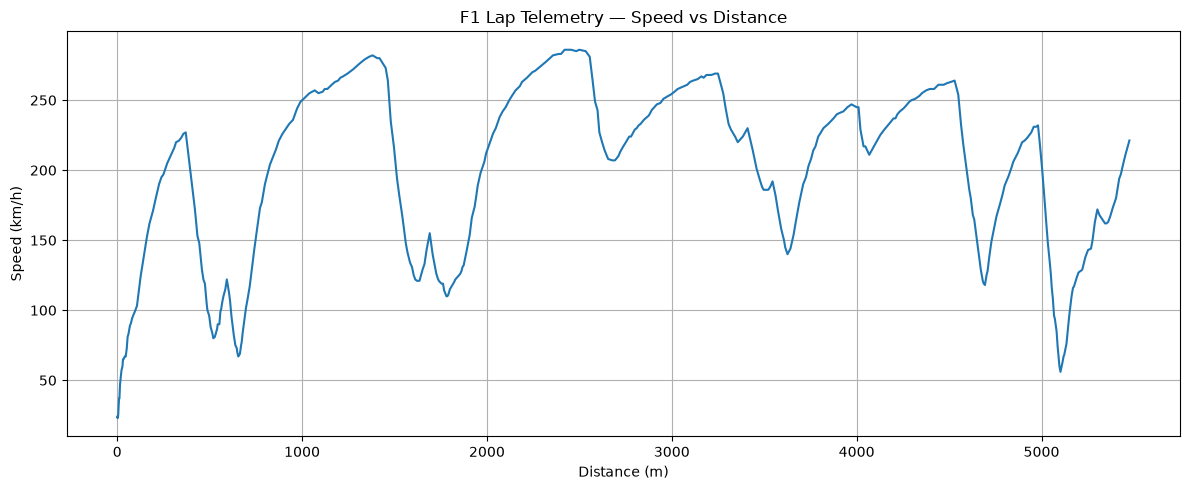

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(telemetry["Distance"], telemetry["Speed"])

plt.xlabel("Distance (m)")
plt.ylabel("Speed (km/h)")
plt.title("F1 Lap Telemetry — Speed vs Distance")
plt.grid(True)
plt.tight_layout()
plt.show()

In [24]:
print("Available telemetry channels:")
print(telemetry.columns.tolist())

Available telemetry channels:
['Time', 'RPM', 'Speed', 'nGear', 'Throttle', 'Brake', 'DRS', 'Distance', 'RelativeDistance', 'DriverAhead', 'DistanceToDriverAhead', 'AccelerationX', 'AccelerationY', 'AccelerationZ', 'X', 'Y', 'Z', 'Driver', 'LapNumber']


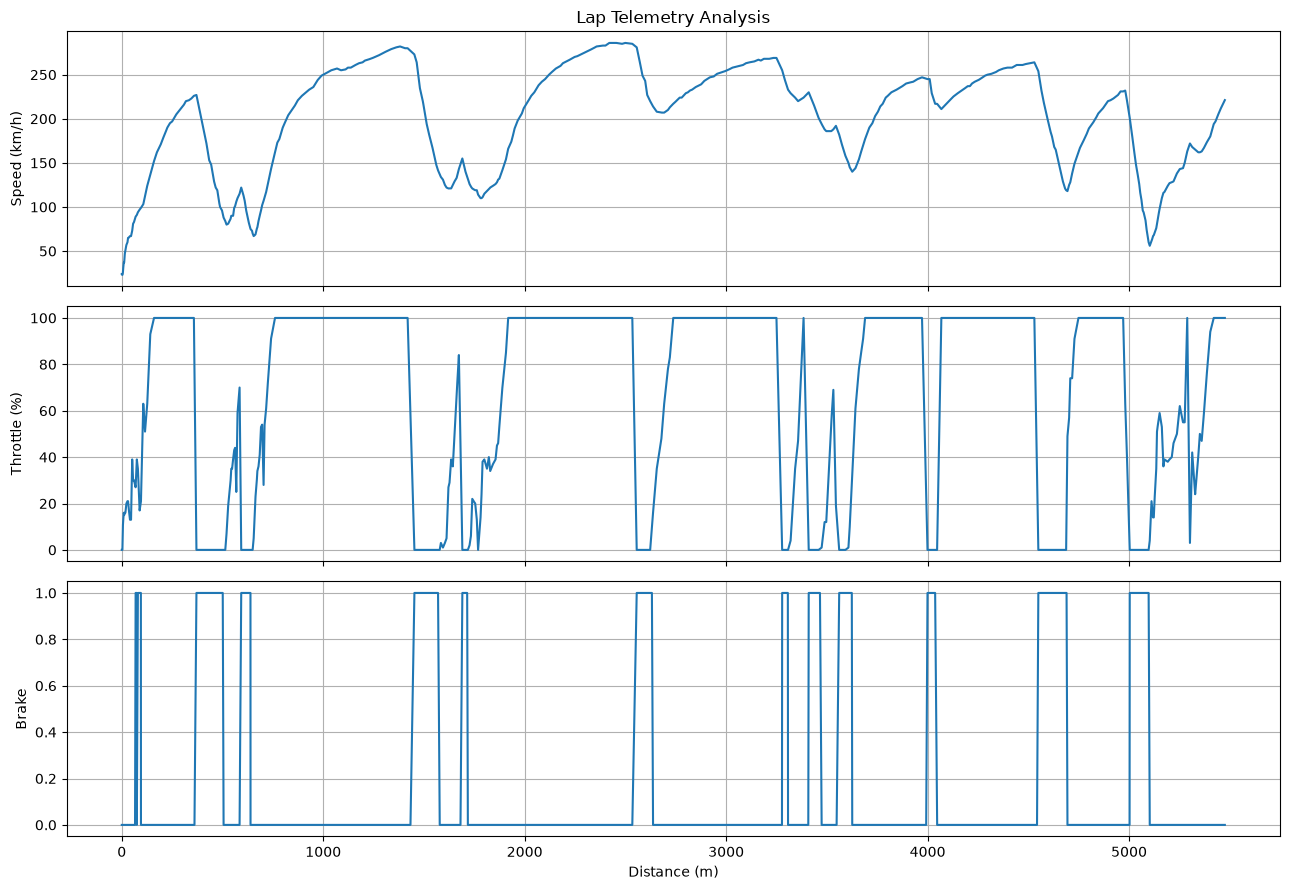

In [25]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

axes[0].plot(telemetry["Distance"], telemetry["Speed"])
axes[0].set_ylabel("Speed (km/h)")
axes[0].set_title("Lap Telemetry Analysis")

axes[1].plot(telemetry["Distance"], telemetry["Throttle"])
axes[1].set_ylabel("Throttle (%)")

axes[2].plot(telemetry["Distance"], telemetry["Brake"])
axes[2].set_ylabel("Brake")
axes[2].set_xlabel("Distance (m)")

for ax in axes:
    ax.grid(True)

plt.tight_layout()
plt.savefig("figures/lap_telemetry_analysis.png", dpi=300)
plt.show()

In [26]:
print(driver.laps[
    ["LapNumber", "LapTime"]
].to_string(index=False))

 LapNumber                LapTime
       1.0                    NaT
       2.0 0 days 00:01:37.518000
       3.0 0 days 00:02:07.966000
       4.0 0 days 00:01:37.420000
       5.0 0 days 00:01:44.223000
       6.0                    NaT
       7.0 0 days 00:01:49.924000
       8.0 0 days 00:01:31.832000
       9.0 0 days 00:01:31.342000
      10.0 0 days 00:01:48.464000
      11.0                    NaT
      12.0 0 days 00:01:27.799000
      13.0 0 days 00:01:55.491000
      14.0 0 days 00:01:27.366000
      15.0 0 days 00:01:37.323000
      16.0                    NaT
      17.0 0 days 00:01:26.796000
      18.0 0 days 00:01:46.676000
      19.0                    NaT
      20.0 0 days 00:01:26.350000
      21.0 0 days 00:01:44.001000
      22.0                    NaT
      23.0 0 days 00:01:26.203000
      24.0                    NaT


In [27]:
lap_a = driver.get_lap(1)
lap_b = driver.get_lap(2)

print("Lap A:", lap_a)
print("Lap B:", lap_b)

Lap A: index                                         73
Time                      0 days 00:15:26.957000
Driver                                       VER
DriverNumber                                   1
LapTime                                      NaT
LapNumber                                    1.0
Stint                                        1.0
PitOutTime                0 days 00:13:37.696000
PitInTime                                    NaT
Sector1Time                                  NaT
Sector2Time               0 days 00:00:43.008000
Sector3Time               0 days 00:00:32.225000
Sector1SessionTime                           NaT
Sector2SessionTime        0 days 00:14:54.901000
Sector3SessionTime        0 days 00:15:26.957000
SpeedI1                                    279.0
SpeedI2                                    232.0
SpeedFL                                    210.0
SpeedST                                    256.0
IsPersonalBest                             False
Compound     

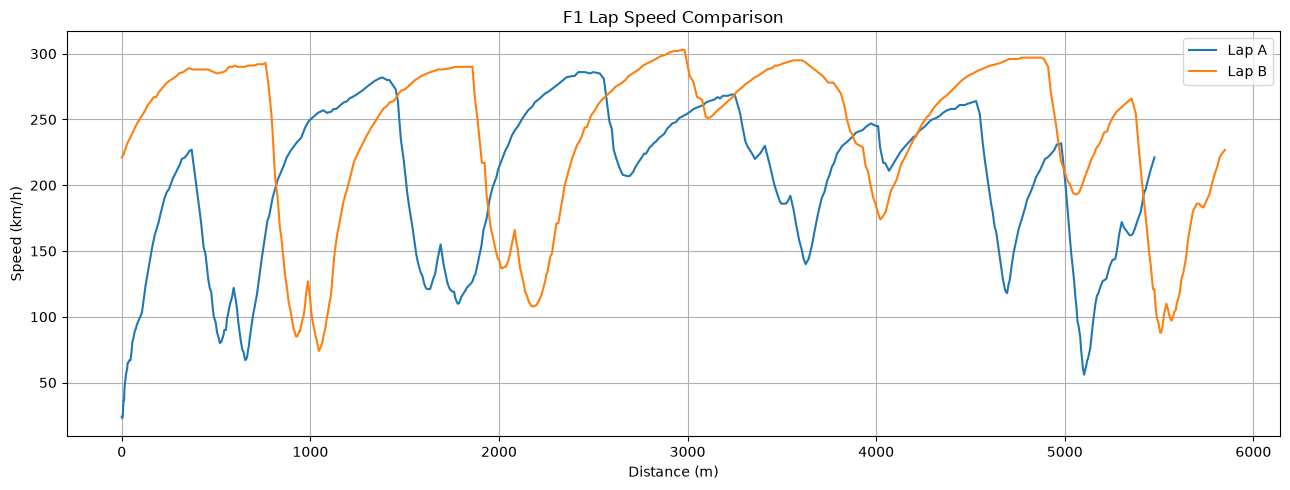

In [28]:
import matplotlib.pyplot as plt

tel_a = lap_a.telemetry
tel_b = lap_b.telemetry

plt.figure(figsize=(13, 5))

plt.plot(
    tel_a["Distance"],
    tel_a["Speed"],
    label="Lap A"
)

plt.plot(
    tel_b["Distance"],
    tel_b["Speed"],
    label="Lap B"
)

plt.xlabel("Distance (m)")
plt.ylabel("Speed (km/h)")
plt.title("F1 Lap Speed Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/lap_speed_comparison.png", dpi=300)
plt.show()

In [29]:
time_a = lap_a["LapTime"].total_seconds()
time_b = lap_b["LapTime"].total_seconds()

difference = time_b - time_a

print(f"Lap A: {time_a:.3f} seconds")
print(f"Lap B: {time_b:.3f} seconds")
print(f"Time difference: {difference:+.3f} seconds")

if difference > 0:
    print(f"Lap A is {difference:.3f} seconds faster.")
elif difference < 0:
    print(f"Lap B is {abs(difference):.3f} seconds faster.")
else:
    print("Both laps have the same lap time.")

Lap A: nan seconds
Lap B: 97.518 seconds
Time difference: +nan seconds
Both laps have the same lap time.


In [30]:
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

print("Saved graphs:")
for file in figures_dir.glob("*.png"):
    print(file)

Saved graphs:
figures\lap_speed_comparison.png
figures\lap_telemetry_analysis.png


In [31]:
import pandas as pd

print("Lap A time:", lap_a["LapTime"])
print("Lap B time:", lap_b["LapTime"])

print("\nAvailable lap information:")
print(
    driver.laps[
        ["LapNumber", "LapTime"]
    ].to_string(index=False)
)

Lap A time: NaT
Lap B time: 0 days 00:01:37.518000

Available lap information:
 LapNumber                LapTime
       1.0                    NaT
       2.0 0 days 00:01:37.518000
       3.0 0 days 00:02:07.966000
       4.0 0 days 00:01:37.420000
       5.0 0 days 00:01:44.223000
       6.0                    NaT
       7.0 0 days 00:01:49.924000
       8.0 0 days 00:01:31.832000
       9.0 0 days 00:01:31.342000
      10.0 0 days 00:01:48.464000
      11.0                    NaT
      12.0 0 days 00:01:27.799000
      13.0 0 days 00:01:55.491000
      14.0 0 days 00:01:27.366000
      15.0 0 days 00:01:37.323000
      16.0                    NaT
      17.0 0 days 00:01:26.796000
      18.0 0 days 00:01:46.676000
      19.0                    NaT
      20.0 0 days 00:01:26.350000
      21.0 0 days 00:01:44.001000
      22.0                    NaT
      23.0 0 days 00:01:26.203000
      24.0                    NaT


In [32]:
valid_laps = driver.laps.dropna(subset=["LapTime"])

print("Number of laps with valid times:", len(valid_laps))
print(valid_laps[["LapNumber", "LapTime"]].head(10))

Number of laps with valid times: 17
    LapNumber                LapTime
1         2.0 0 days 00:01:37.518000
2         3.0 0 days 00:02:07.966000
3         4.0 0 days 00:01:37.420000
4         5.0 0 days 00:01:44.223000
6         7.0 0 days 00:01:49.924000
7         8.0 0 days 00:01:31.832000
8         9.0 0 days 00:01:31.342000
9        10.0 0 days 00:01:48.464000
11       12.0 0 days 00:01:27.799000
12       13.0 0 days 00:01:55.491000


In [33]:
valid_laps = driver.laps.dropna(subset=["LapTime"])

fastest_two = valid_laps.sort_values("LapTime").head(2)

print(
    fastest_two[["LapNumber", "LapTime"]].to_string(index=False)
)

 LapNumber                LapTime
      23.0 0 days 00:01:26.203000
      20.0 0 days 00:01:26.350000


In [34]:
lap_a = fastest_two.iloc[0]
lap_b = fastest_two.iloc[1]

time_a = lap_a["LapTime"].total_seconds()
time_b = lap_b["LapTime"].total_seconds()

difference = time_b - time_a

print(f"Fastest lap: {time_a:.3f} seconds")
print(f"Second-fastest lap: {time_b:.3f} seconds")
print(f"Time difference: {difference:.3f} seconds")

Fastest lap: 86.203 seconds
Second-fastest lap: 86.350 seconds
Time difference: 0.147 seconds


In [35]:
print("Available lap columns:")
print(driver.laps.columns.tolist())

Available lap columns:
['index', 'Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate', 'WeatherTime', 'AirTemp', 'Humidity', 'Pressure', 'Rainfall', 'TrackTemp', 'WindDirection', 'WindSpeed', 'LapTimeSeconds', 'QualifyingSession', 'ms1', 'ms2', 'ms3', 'drv', 'team']


In [36]:
sector_columns = [
    col for col in driver.laps.columns
    if "Sector" in col or "sector" in col
]

print("Sector columns found:", sector_columns)

if sector_columns:
    print(
        driver.laps[
            ["LapNumber", "LapTime"] + sector_columns
        ].head(10).to_string(index=False)
    )
else:
    print("No sector columns found in this dataset.")

Sector columns found: ['Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime']
 LapNumber                LapTime            Sector1Time            Sector2Time            Sector3Time     Sector1SessionTime     Sector2SessionTime     Sector3SessionTime
       1.0                    NaT                    NaT 0 days 00:00:43.008000 0 days 00:00:32.225000                    NaT 0 days 00:14:54.901000 0 days 00:15:26.957000
       2.0 0 days 00:01:37.518000 0 days 00:00:31.362000 0 days 00:00:39.005000 0 days 00:00:27.151000 0 days 00:15:58.319000 0 days 00:16:37.324000 0 days 00:17:04.475000
       3.0 0 days 00:02:07.966000 0 days 00:00:38.475000 0 days 00:00:54.234000 0 days 00:00:35.257000 0 days 00:17:42.950000 0 days 00:18:37.184000 0 days 00:19:12.441000
       4.0 0 days 00:01:37.420000 0 days 00:00:30.778000 0 days 00:00:39.251000 0 days 00:00:27.391000 0 days 00:19:43.219000 0 days 00:20:22.470000 0 days 00:20:49.861000
      

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

valid = driver.laps.dropna(
    subset=["LapTime", "Sector1Time", "Sector2Time", "Sector3Time"]
).copy()

valid["LapSeconds"] = valid["LapTime"].dt.total_seconds()

for col in ["Sector1Time", "Sector2Time", "Sector3Time"]:
    valid[col + "Seconds"] = valid[col].dt.total_seconds()

# Select the two fastest laps with complete sector data
two_laps = valid.nsmallest(2, "LapTime").sort_values("LapTime")

print(two_laps[
    ["LapNumber", "LapSeconds",
     "Sector1TimeSeconds", "Sector2TimeSeconds",
     "Sector3TimeSeconds"]
].to_string(index=False))

 LapNumber  LapSeconds  Sector1TimeSeconds  Sector2TimeSeconds  Sector3TimeSeconds
      23.0      86.203              28.136              34.587              23.480
      20.0      86.350              28.036              34.712              23.602


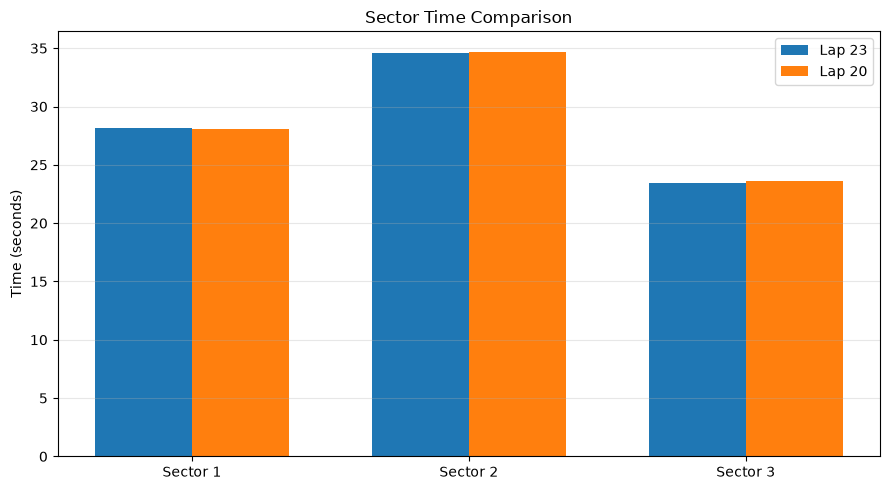

In [38]:
sector_cols = [
    "Sector1TimeSeconds",
    "Sector2TimeSeconds",
    "Sector3TimeSeconds"
]

labels = ["Sector 1", "Sector 2", "Sector 3"]

lap_a_sectors = two_laps.iloc[0][sector_cols].astype(float).values
lap_b_sectors = two_laps.iloc[1][sector_cols].astype(float).values

x = range(3)
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(
    [i - width / 2 for i in x],
    lap_a_sectors,
    width,
    label=f"Lap {int(two_laps.iloc[0]['LapNumber'])}"
)
plt.bar(
    [i + width / 2 for i in x],
    lap_b_sectors,
    width,
    label=f"Lap {int(two_laps.iloc[1]['LapNumber'])}"
)

plt.xticks(list(x), labels)
plt.ylabel("Time (seconds)")
plt.title("Sector Time Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("figures/sector_comparison.png", dpi=300)
plt.show()

In [39]:
for label, a, b in zip(labels, lap_a_sectors, lap_b_sectors):
    delta = b - a
    result = "slower" if delta > 0 else "faster" if delta < 0 else "equal"
    print(f"{label}: Lap B is {abs(delta):.3f} s {result} than Lap A")

Sector 1: Lap B is 0.100 s faster than Lap A
Sector 2: Lap B is 0.125 s slower than Lap A
Sector 3: Lap B is 0.122 s slower than Lap A


In [40]:
import pandas as pd
from pathlib import Path

sector_names = ["Sector 1", "Sector 2", "Sector 3"]

results = pd.DataFrame({
    "Sector": sector_names,
    "Lap A (s)": lap_a_sectors,
    "Lap B (s)": lap_b_sectors,
})

results["Difference (s)"] = (
    results["Lap B (s)"] - results["Lap A (s)"]
)

results["Outcome"] = results["Difference (s)"].apply(
    lambda x: "Faster" if x < 0 else "Slower" if x > 0 else "Equal"
)

results.to_csv("figures/sector_analysis.csv", index=False)

display(results.round(3))
print("Sector analysis saved successfully.")

,Sector,Lap A (s),Lap B (s),Difference (s),Outcome
0,Sector 1,28.136,28.036,-0.100,Faster
1,Sector 2,34.587,34.712,0.125,Slower
2,Sector 3,23.480,23.602,0.122,Slower


Sector analysis saved successfully.


In [41]:
from pathlib import Path

project_dir = Path.cwd()

folders = [
    "data/cache",
    "figures",
    "reports",
    "src"
]

for folder in folders:
    (project_dir / folder).mkdir(parents=True, exist_ok=True)

print("Project structure:")
for folder in folders:
    print(f"  {folder}/")

print("\nProject location:", project_dir.resolve())

Project structure:
  data/cache/
  figures/
  reports/
  src/

Project location: C:\Users\yazda


In [42]:
from pathlib import Path

print("Existing figure files:")
for file in sorted(Path("figures").glob("*")):
    print(f"  {file.name}")

print("\nCurrent analysis variables:")
for name in [
    "session", "driver", "lap_a", "lap_b",
    "telemetry", "lap_a_sectors", "lap_b_sectors"
]:
    print(f"  {name}: {'available' if name in globals() else 'not available'}")

Existing figure files:
  lap_speed_comparison.png
  lap_telemetry_analysis.png
  sector_analysis.csv
  sector_comparison.png

Current analysis variables:
  session: available
  driver: available
  lap_a: available
  lap_b: available
  telemetry: available
  lap_a_sectors: available
  lap_b_sectors: available


In [43]:
import importlib
import analysis

importlib.reload(analysis)

result = analysis.compare_lap_times(lap_a, lap_b)
print(result)

ModuleNotFoundError: No module named 'analysis'

In [44]:
from pathlib import Path

print("Notebook is running in:")
print(Path.cwd())

print("\nPython files in this folder:")
for file in Path.cwd().glob("*.py"):
    print(file.name)

Notebook is running in:
C:\Users\yazda

Python files in this folder:


In [45]:
from pathlib import Path

code = '''
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd


def compare_lap_times(lap_a, lap_b):
    """Compare two laps using their recorded lap times."""
    time_a = lap_a["LapTime"].total_seconds()
    time_b = lap_b["LapTime"].total_seconds()

    if pd.isna(time_a) or pd.isna(time_b):
        raise ValueError("Both laps must have valid lap times.")

    return {
        "lap_a_seconds": time_a,
        "lap_b_seconds": time_b,
        "difference_seconds": time_b - time_a,
    }


def plot_speed_comparison(
    telemetry_a,
    telemetry_b,
    label_a="Lap A",
    label_b="Lap B",
    output_path="figures/lap_speed_comparison.png",
):
    """Plot speed against distance for two laps."""
    required = {"Distance", "Speed"}

    for label, telemetry in [
        (label_a, telemetry_a),
        (label_b, telemetry_b),
    ]:
        missing = required - set(telemetry.columns)
        if missing:
            raise ValueError(
                f"{label} is missing columns: {sorted(missing)}"
            )

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(telemetry_a["Distance"], telemetry_a["Speed"], label=label_a)
    ax.plot(telemetry_b["Distance"], telemetry_b["Speed"], label=label_b)

    ax.set(
        xlabel="Distance (m)",
        ylabel="Speed (km/h)",
        title="Lap Speed Comparison",
    )
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()

    output = Path(output_path)
    output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=300, bbox_inches="tight")

    return fig, ax
'''

Path("analysis.py").write_text(code.strip() + "\n", encoding="utf-8")

print("Created:", Path("analysis.py").resolve())

Created: C:\Users\yazda\analysis.py


In [46]:
import importlib
import analysis

importlib.reload(analysis)

print("Analysis module imported successfully!")

Analysis module imported successfully!


In [47]:
result = analysis.compare_lap_times(lap_a, lap_b)

print("Lap A:", result["lap_a_seconds"], "seconds")
print("Lap B:", result["lap_b_seconds"], "seconds")
print(
    "Time difference:",
    round(result["difference_seconds"], 3),
    "seconds"
)

Lap A: 86.203 seconds
Lap B: 86.35 seconds
Time difference: 0.147 seconds


CDN jsDelivr failed: Network request failed: url='https://cdn.jsdelivr.net/gh/TracingInsights/2024@main/British%20Grand%20Prix/Qualifying/VER/23_tel.json'


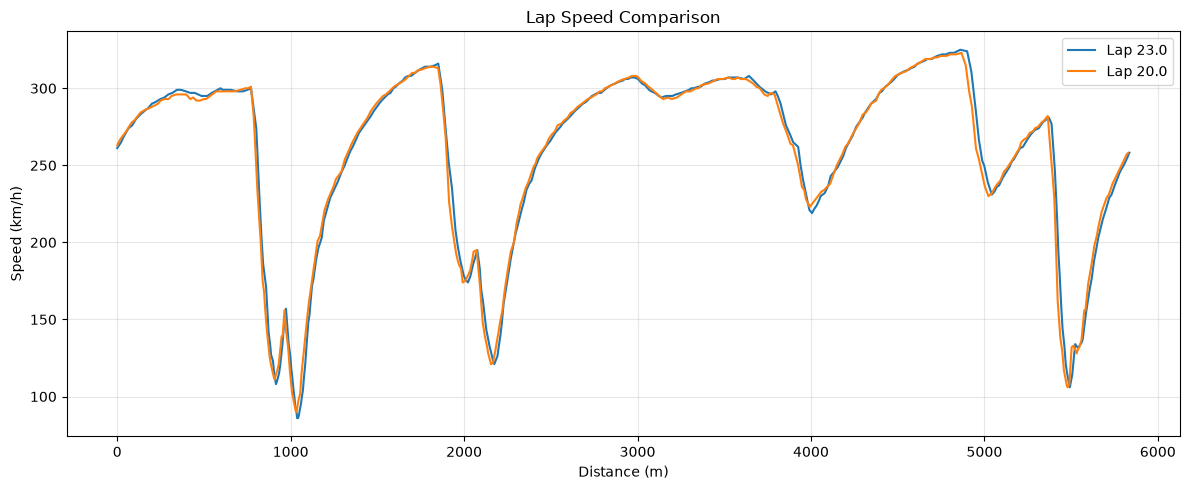

In [48]:
fig, ax = analysis.plot_speed_comparison(
    lap_a.telemetry,
    lap_b.telemetry,
    label_a=f"Lap {lap_a['LapNumber']}",
    label_b=f"Lap {lap_b['LapNumber']}",
)

import matplotlib.pyplot as plt
plt.show()

In [49]:
print("Lap A telemetry rows:", len(lap_a.telemetry))
print("Lap B telemetry rows:", len(lap_b.telemetry))

print("\nMissing values in Lap A:")
print(lap_a.telemetry[["Distance", "Speed"]].isna().sum())

print("\nMissing values in Lap B:")
print(lap_b.telemetry[["Distance", "Speed"]].isna().sum())

Lap A telemetry rows: 659
Lap B telemetry rows: 661

Missing values in Lap A:
Distance    0
Speed       0
dtype: int64

Missing values in Lap B:
Distance    0
Speed       0
dtype: int64


In [50]:
from pathlib import Path

graph = Path("figures/lap_speed_comparison.png")

print("Graph exists:", graph.exists())

if graph.exists():
    print("File size:", graph.stat().st_size, "bytes")

Graph exists: True
File size: 247585 bytes


In [51]:
import importlib
import analysis

importlib.reload(analysis)

sector_results = analysis.compare_sectors(lap_a, lap_b)
display(sector_results.round(3))

,Sector,Lap A (s),Lap B (s),Difference (s)
0,Sector1,28.136,28.036,-0.100
1,Sector2,34.587,34.712,0.125
2,Sector3,23.480,23.602,0.122


In [52]:
from pathlib import Path
from datetime import datetime

import pandas as pd

# Calculate lap-time comparison
time_a = lap_a["LapTime"].total_seconds()
time_b = lap_b["LapTime"].total_seconds()

if pd.isna(time_a) or pd.isna(time_b):
    raise ValueError("Select two laps with valid lap times.")

difference = time_b - time_a

# Calculate sector comparison
sector_results = analysis.compare_sectors(lap_a, lap_b)

# Build report
report = f"""
# F1 Lap Telemetry Analysis Report

## Project overview
This report compares two laps from the selected F1 session
using historical lap timing and telemetry data.

## Lap comparison
- Lap A: {lap_a['LapNumber']}
- Lap B: {lap_b['LapNumber']}
- Lap A time: {time_a:.3f} seconds
- Lap B time: {time_b:.3f} seconds
- Lap B minus Lap A: {difference:+.3f} seconds

"""

if difference > 0:
    report += "Lap B was slower than Lap A.\n"
elif difference < 0:
    report += "Lap B was faster than Lap A.\n"
else:
    report += "Both laps recorded the same lap time.\n"

report += "\n## Sector comparison\n\n"
report += sector_results.round(3).to_markdown(index=False)
report += """

## Interpretation
Positive sector differences mean Lap B took longer.
Negative sector differences mean Lap B was faster.

Sector timing identifies where time differences occurred,
but further telemetry analysis is needed to determine why.

## Limitations
- This is a historical data analysis, not a live telemetry system.
- Data completeness and validity affect the conclusions.
- Tyres, traffic, weather and track conditions may influence
  lap-to-lap comparisons.
"""

report_path = Path("reports/lap_analysis_report.md")
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(report.strip() + "\n", encoding="utf-8")

print("Report generated:", report_path.resolve())
print(report)

ImportError: Missing optional dependency 'tabulate'.  Use pip or conda to install tabulate.

In [53]:
%pip install tabulate

Note: you may need to restart the kernel to use updated packages.


In [54]:
from pathlib import Path
from datetime import datetime

import pandas as pd

# Calculate lap-time comparison
time_a = lap_a["LapTime"].total_seconds()
time_b = lap_b["LapTime"].total_seconds()

if pd.isna(time_a) or pd.isna(time_b):
    raise ValueError("Select two laps with valid lap times.")

difference = time_b - time_a

# Calculate sector comparison
sector_results = analysis.compare_sectors(lap_a, lap_b)

# Build report
report = f"""
# F1 Lap Telemetry Analysis Report

## Project overview
This report compares two laps from the selected F1 session
using historical lap timing and telemetry data.

## Lap comparison
- Lap A: {lap_a['LapNumber']}
- Lap B: {lap_b['LapNumber']}
- Lap A time: {time_a:.3f} seconds
- Lap B time: {time_b:.3f} seconds
- Lap B minus Lap A: {difference:+.3f} seconds

"""

if difference > 0:
    report += "Lap B was slower than Lap A.\n"
elif difference < 0:
    report += "Lap B was faster than Lap A.\n"
else:
    report += "Both laps recorded the same lap time.\n"

report += "\n## Sector comparison\n\n"
report += sector_results.round(3).to_markdown(index=False)
report += """

## Interpretation
Positive sector differences mean Lap B took longer.
Negative sector differences mean Lap B was faster.

Sector timing identifies where time differences occurred,
but further telemetry analysis is needed to determine why.

## Limitations
- This is a historical data analysis, not a live telemetry system.
- Data completeness and validity affect the conclusions.
- Tyres, traffic, weather and track conditions may influence
  lap-to-lap comparisons.
"""

report_path = Path("reports/lap_analysis_report.md")
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(report.strip() + "\n", encoding="utf-8")

print("Report generated:", report_path.resolve())
print(report)

Report generated: C:\Users\yazda\reports\lap_analysis_report.md

# F1 Lap Telemetry Analysis Report

## Project overview
This report compares two laps from the selected F1 session
using historical lap timing and telemetry data.

## Lap comparison
- Lap A: 23.0
- Lap B: 20.0
- Lap A time: 86.203 seconds
- Lap B time: 86.350 seconds
- Lap B minus Lap A: +0.147 seconds

Lap B was slower than Lap A.

## Sector comparison

| Sector   |   Lap A (s) |   Lap B (s) |   Difference (s) |
|:---------|------------:|------------:|-----------------:|
| Sector1  |      28.136 |      28.036 |           -0.1   |
| Sector2  |      34.587 |      34.712 |            0.125 |
| Sector3  |      23.48  |      23.602 |            0.122 |

## Interpretation
Positive sector differences mean Lap B took longer.
Negative sector differences mean Lap B was faster.

Sector timing identifies where time differences occurred,
but further telemetry analysis is needed to determine why.

## Limitations
- This is a historical

In [55]:
from pathlib import Path

readme = """# F1 Lap Telemetry Analysis

## Overview
A Python-based motorsport data analysis project that compares
historical Formula 1 lap performance using lap timing and telemetry.

## Features
- Speed versus distance visualization
- Throttle and braking analysis
- Lap-time comparison
- Sector-by-sector time deltas
- Automated Markdown engineering report
- Exported figures and CSV results

## Tools and Technologies
- Python
- Jupyter Notebook
- TIF1
- pandas
- NumPy
- Matplotlib

## Project Structure
- `data/` — cached or downloaded data
- `figures/` — plots and sector analysis results
- `reports/` — generated engineering reports
- `analysis.py` — reusable analysis functions
- `lap_telemetry_analysis.ipynb` — analysis notebook

## Methodology
Lap times and sector times are compared to identify where
time is gained or lost. Telemetry plots help investigate
speed, throttle and braking behaviour.

## Limitations
This project uses historical data and is not a live telemetry
system. Lap comparisons can be affected by tyre condition,
traffic, weather, and data completeness.

## Reproducibility
Install the required Python packages and run the notebook
in an environment with access to the selected data source.

## Disclaimer
This is an independent educational project and is not
affiliated with Formula 1 or any F1 team.
"""

Path("README.md").write_text(readme, encoding="utf-8")

print("README created at:", Path("README.md").resolve())

README created at: C:\Users\yazda\README.md


In [56]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("\nPython files:")
for file in Path.cwd().glob("*.py"):
    print(" -", file.name)

print("\nNotebook files:")
for file in Path.cwd().glob("*.ipynb"):
    print(" -", file.name)

print("\nProject folders:")
for folder in ["figures", "reports", "data"]:
    path = Path(folder)
    if path.exists():
        print(f" - {folder}: exists")
    else:
        print(f" - {folder}: not found")

print("\nREADME exists:", Path("README.md").exists())

Current folder: C:\Users\yazda

Python files:
 - analysis.py

Notebook files:
 - lap_telemetry_analysis.ipynb

Project folders:
 - figures: exists
 - reports: exists
 - data: exists

README exists: True
